In [68]:
"""案例:通过KNN算法实现鸢尾花的分类操作"""
#导包
from sklearn.datasets import load_iris#加载鸢尾花测试集
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split#分割训练集和测试集
from sklearn.preprocessing import StandardScaler#数据标准化的
from sklearn.neighbors import KNeighborsClassifier#KNN算法,分类对象
from sklearn.metrics import accuracy_score#模型评估,计算模型预测的准确率


In [69]:
#1.定义函数,加载鸢尾花数据集
def dem01_loadiris():
    #加载鸢尾花数据集
    iris_data=load_iris()
    #查看数据集
    #print(f"数据集:{iris_data}")#字典形态
    print(f"数据集类型:{type(iris_data)}")#<class 'sklearn.utils._bunch.Bunch'>
    #查看所有的键
    print(f"数据集中所有的键{iris_data.keys()}")
    #查看数据集中的键对应的值
    print(f"具体的数据{iris_data.data[:5]}")#只看前五条
    print(f"具体的标签:{iris_data.target[:5]}")
    print(f"标签对应的名称:{iris_data.target_names}")#['setosa' 'versicolor' 'virginica']
    print(f"特征对应的名称{iris_data.feature_names}")
    print(f"数据集的框架:{iris_data.frame}")#None
    # print(f" 数据集的文件名:{iris_data.filename}")#iris.csv
    # print(f"数据集的模型在那个包下:{iris_data.data_module}")#sklearn.datasets.data
    #print(f"数据集的描述:{iris_data.DESCR}")

dem01_loadiris()  

数据集类型:<class 'sklearn.utils._bunch.Bunch'>
数据集中所有的键dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
具体的数据[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
具体的标签:[0 0 0 0 0]
标签对应的名称:['setosa' 'versicolor' 'virginica']
特征对应的名称['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
数据集的框架:None


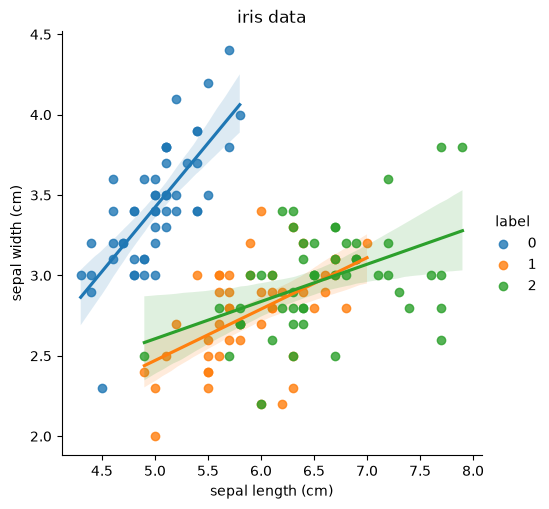

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     label  
0        0  
1

In [70]:
#定义函数,绘制数据散点图
def dem02_showiris():
    #加载数据集
    iris_data=load_iris()
    #把鸢尾花数据集封装成DataFrame对象
    iris_df=pd.DataFrame(iris_data.data,columns=iris_data.feature_names)
    #新增标签列
    iris_df['label']=iris_data.target
    #绘制散点图
    #参1数据集,参2,x,参三y,参4分组字段,参五是否显示拟合直线
    sns.lmplot(data=iris_df,x="sepal length (cm)" ,y="sepal width (cm)",hue="label",fit_reg=True)
    #设置标题,显示
    plt.title("iris data")
    plt.show()
    print(iris_df)
dem02_showiris()    



In [71]:
#定义函数,切分训练集和测试机
def dem03_split_train_test():
    #加载数据集
    iris_data=load_iris()
    #数据预处理,从150个数据中,按照8:2的比例,切分训练集与数据集
    x_train,x_test,y_train,y_test=train_test_split(iris_data.data,iris_data.target,test_size=0.2,random_state=42)
    #打印切割后的结果
    print(f"训练集的特征:{x_train},个数{len(x_train)}")
    print(f"训练集的特征:{y_train},个数{len(y_train)}")
    print(f"测试集的特征:{x_test},个数{len(x_test)}")
    print(f"测试集的特征:{y_test},个数{len(y_test)}")
    

dem03_split_train_test()    


训练集的特征:[[4.6 3.6 1.  0.2]
 [5.7 4.4 1.5 0.4]
 [6.7 3.1 4.4 1.4]
 [4.8 3.4 1.6 0.2]
 [4.4 3.2 1.3 0.2]
 [6.3 2.5 5.  1.9]
 [6.4 3.2 4.5 1.5]
 [5.2 3.5 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.2 4.1 1.5 0.1]
 [5.8 2.7 5.1 1.9]
 [6.  3.4 4.5 1.6]
 [6.7 3.1 4.7 1.5]
 [5.4 3.9 1.3 0.4]
 [5.4 3.7 1.5 0.2]
 [5.5 2.4 3.7 1. ]
 [6.3 2.8 5.1 1.5]
 [6.4 3.1 5.5 1.8]
 [6.6 3.  4.4 1.4]
 [7.2 3.6 6.1 2.5]
 [5.7 2.9 4.2 1.3]
 [7.6 3.  6.6 2.1]
 [5.6 3.  4.5 1.5]
 [5.1 3.5 1.4 0.2]
 [7.7 2.8 6.7 2. ]
 [5.8 2.7 4.1 1. ]
 [5.2 3.4 1.4 0.2]
 [5.  3.5 1.3 0.3]
 [5.1 3.8 1.9 0.4]
 [5.  2.  3.5 1. ]
 [6.3 2.7 4.9 1.8]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.1 3.3 1.7 0.5]
 [5.6 2.7 4.2 1.3]
 [5.1 3.4 1.5 0.2]
 [5.7 3.  4.2 1.2]
 [7.7 3.8 6.7 2.2]
 [4.6 3.2 1.4 0.2]
 [6.2 2.9 4.3 1.3]
 [5.7 2.5 5.  2. ]
 [5.5 4.2 1.4 0.2]
 [6.  3.  4.8 1.8]
 [5.8 2.7 5.1 1.9]
 [6.  2.2 4.  1. ]
 [5.4 3.  4.5 1.5]
 [6.2 3.4 5.4 2.3]
 [5.5 2.3 4.  1.3]
 [5.4 3.9 1.7 0.4]
 [5.  2.3 3.3 1. ]
 [6.4 2.7 5.3 1.9]
 [5.  3.3 1.4 0.2]
 [5. 

In [72]:
#利用KNN算法对鸢尾花分类_模型评估
#获取数据集
def dem04_iris_evaluate_test():
    #加载数据集
    iris_data=load_iris()
    x_train,x_test,y_train,y_test=train_test_split(iris_data.data,iris_data.target,test_size=0.2,random_state=25)
    #特征预处理
    #1:原来4个特征值无需特恒处理
    #2:特征预处理:原数据的4列特征值差值不大,无需特征预处理,但是,加入特征预处理会让代码更完善
    transfer=StandardScaler()
    #对特征进行标准化,即x_train:训练集的特征数据,x_test:测试集的特征数据
    #fit_transform:兼具fit和transform的功能,即:训练,转换,该函数适用于:第一次标准化时使用
    x_train=transfer.fit_transform(x_train)
    x_test=transfer.transform(x_test)
    #模型训练
    estimator=KNeighborsClassifier(n_neighbors=3)
    estimator.fit(x_train,y_train)
    #1:对刚才切分的测试集(30条)进行测试
    y_prd=estimator.predict(x_test)
    print(y_prd)
    #自定义测试
    my_data=[[7.8,2.1,3.6,1.6]]
    #标准化
    my_data=transfer.transform(my_data)
    y1_prd=estimator.predict(my_data)
    print(y1_prd)
    #查找上述数据集,每种分类的预测概率
    y_pre_proba=estimator.predict_proba(my_data)
    print(f"(各分类)预测概率为:{y_pre_proba}")
    #模型评估
    #1:直接评分
    print(f"正确率:{estimator.score(x_train,y_train)}")
    #2:基于测试集的标签和预测结果进行评分
    print(f"正确率:{accuracy_score(y_test,y_prd)}")
    
dem04_iris_evaluate_test()   


[0 2 2 1 2 1 2 0 1 1 0 0 0 1 0 1 2 2 1 1 1 1 1 0 0 2 1 2 2 0]
[1]
(各分类)预测概率为:[[0.         0.66666667 0.33333333]]
正确率:0.9666666666666667
正确率:0.9
